# Named Entity Recognition on CoNLL-2003
LSTM, BiLSTM and BiLSTM+CRF (PyTorch, GloVe + char-CNN) compared with fine-tuned DistilBERT and BERT-base-cased.

- Demo: https://huggingface.co/spaces/mai-data-ai/ner-app
- Model: https://huggingface.co/mai-data-ai/ner-bert-base-cased-conll2003


## 1. Load the dataset
CoNLL-2003 from the Hugging Face Parquet export (the original loading script is no longer supported).

In [2]:
from datasets import load_dataset

ds = load_dataset("eriktks/conll2003", revision="refs/convert/parquet")
print(ds)

label_names = ds["train"].features["ner_tags"].feature.names
print(label_names)

ex = ds["train"][0]
for tok, tag in zip(ex["tokens"], ex["ner_tags"]):
    print(f"{tok:15} {label_names[tag]}")

conll2003/train/0000.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

conll2003/train/0000.parquet: downloading bytes:           |  0.00B            

0000.parquet:   0%|          | 0.00/312k [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/283k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3453
    })
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
EU              B-ORG
rejects         O
German          B-MISC
call            O
to              O
boycott         O
British         B-MISC
lamb            O
.               O


In [5]:
ds.save_to_disk("/content/conll2003_local")

# Optional: keep a copy on Drive
from google.colab import drive
drive.mount('/content/drive')
!cp -r /content/conll2003_local /content/drive/MyDrive/conll2003_local

Saving the dataset (0/1 shards):   0%|          | 0/14041 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/3250 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/3453 [00:00<?, ? examples/s]

Mounted at /content/drive


## 2. Exploratory analysis

Sentence length -> mean: 14.5 | max: 113 | 95th pct: 37
      tag   count
1       O  169578
5   B-LOC    7140
3   B-PER    6600
0   B-ORG    6321
4   I-PER    4528
6   I-ORG    3704
2  B-MISC    3438
8   I-LOC    1157
7  I-MISC    1155
Entities per type: {'PER': 6600, 'ORG': 6321, 'LOC': 7140, 'MISC': 3438}


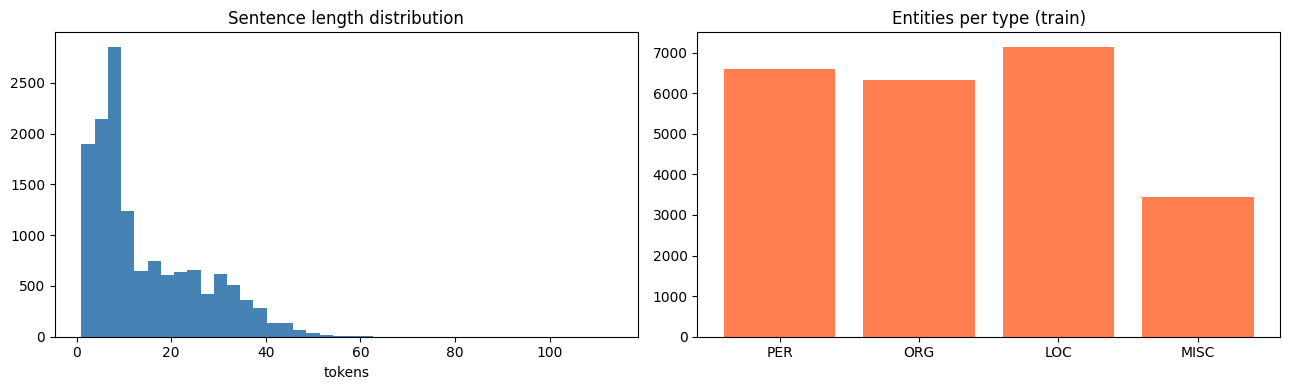

'O' tokens: 83.3%
Vocab size (train): 23623


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

label_names = ds["train"].features["ner_tags"].feature.names

# 1) Sentence length
lens = [len(x) for x in ds["train"]["tokens"]]
print("Sentence length -> mean: %.1f | max: %d | 95th pct: %d" %
      (sum(lens)/len(lens), max(lens), pd.Series(lens).quantile(0.95)))

# 2) Tag distribution (token level)
tag_counts = Counter(t for tags in ds["train"]["ner_tags"] for t in tags)
tag_df = pd.DataFrame({
    "tag": [label_names[i] for i in tag_counts],
    "count": list(tag_counts.values())
}).sort_values("count", ascending=False)
print(tag_df)

# 3) Number of entities per type (count B- tags only)
ent_counts = {l.split("-")[1]: tag_counts[i]
              for i, l in enumerate(label_names) if l.startswith("B-")}
print("Entities per type:", ent_counts)

# 4) Plots
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(lens, bins=40, color="steelblue")
ax[0].set_title("Sentence length distribution")
ax[0].set_xlabel("tokens")
ax[1].bar(ent_counts.keys(), ent_counts.values(), color="coral")
ax[1].set_title("Entities per type (train)")
plt.tight_layout(); plt.show()

# 5) Share of 'O' tokens
o_ratio = tag_counts[0] / sum(tag_counts.values())
print(f"'O' tokens: {o_ratio:.1%}")

# 6) Vocabulary size (relevant for OOV handling and char embeddings)
vocab = Counter(w for s in ds["train"]["tokens"] for w in s)
print("Vocab size (train):", len(vocab))

## 3. Vocabulary, GloVe embeddings, character vocabulary and DataLoaders

In [7]:
!pip install -q gensim pytorch-crf

import random, pickle, os
import torch, numpy as np
from collections import Counter
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset, DataLoader
import gensim.downloader as api
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
# ---------- seed ----------

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)


device: cuda


In [9]:
# ---------- GloVe ----------
glove = api.load("glove-wiki-gigaword-100")
EMB_DIM = 100


[==================================================] 100.0% 128.1/128.1MB downloaded


In [10]:
# ---------- Word vocab ----------
train_words = Counter(w.lower() for s in ds["train"]["tokens"] for w in s)
word2idx = {"<PAD>": 0, "<UNK>": 1}
for w in train_words:
    word2idx[w] = len(word2idx)
for split in ["validation", "test"]:
    for s in ds[split]["tokens"]:
        for w in s:
            w = w.lower()
            if w not in word2idx and w in glove.key_to_index:
                word2idx[w] = len(word2idx)
print("word vocab:", len(word2idx))

word vocab: 25543


In [11]:
# ---------- Embedding matrix ----------
emb = np.random.normal(0, 0.1, (len(word2idx), EMB_DIM)).astype("float32")
emb[0] = 0
hit = 0
for w, i in word2idx.items():
    if w in glove.key_to_index:
        emb[i] = glove[w]; hit += 1
print(f"GloVe coverage: {hit/len(word2idx):.1%}")
emb_matrix = torch.tensor(emb)

GloVe coverage: 89.8%


In [12]:
# ---------- Char vocab ----------
chars = Counter(c for s in ds["train"]["tokens"] for w in s for c in w)
char2idx = {"<PAD>": 0, "<UNK>": 1}
for c in chars:
    char2idx[c] = len(char2idx)
print("char vocab:", len(char2idx))

char vocab: 86


In [13]:
# ---------- Save artifacts ----------
os.makedirs("/content/drive/MyDrive/ner_artifacts", exist_ok=True)
with open("/content/drive/MyDrive/ner_artifacts/vocab.pkl", "wb") as f:
    pickle.dump({"word2idx": word2idx, "char2idx": char2idx,
                 "label_names": label_names}, f)
torch.save(emb_matrix, "/content/drive/MyDrive/ner_artifacts/emb_matrix.pt")

In [14]:
# ---------- Dataset + DataLoaders ----------
class NERDataset(Dataset):
    def __init__(self, split):
        self.data = ds[split]
    def __len__(self):
        return len(self.data)
    def __getitem__(self, i):
        toks, tags = self.data[i]["tokens"], self.data[i]["ner_tags"]
        w = torch.tensor([word2idx.get(t.lower(), 1) for t in toks])
        c = [torch.tensor([char2idx.get(ch, 1) for ch in t[:20]]) for t in toks]
        return w, c, torch.tensor(tags)

def collate(batch):
    ws, cs, ts = zip(*batch)
    words = pad_sequence(ws, batch_first=True, padding_value=0)
    tags  = pad_sequence(ts, batch_first=True, padding_value=0)
    mask  = words != 0
    B, T = words.shape
    max_c = max(len(tok) for sent in cs for tok in sent)
    chars_t = torch.zeros(B, T, max_c, dtype=torch.long)
    for b, sent in enumerate(cs):
        for t, tok in enumerate(sent):
            chars_t[b, t, :len(tok)] = tok
    return words, chars_t, tags, mask

train_dl = DataLoader(NERDataset("train"),      batch_size=32, shuffle=True,  collate_fn=collate)
val_dl   = DataLoader(NERDataset("validation"), batch_size=64, shuffle=False, collate_fn=collate)
test_dl  = DataLoader(NERDataset("test"),       batch_size=64, shuffle=False, collate_fn=collate)

w, c, t, m = next(iter(train_dl))
print(w.shape, c.shape, t.shape, m.shape)

torch.Size([32, 47]) torch.Size([32, 47, 13]) torch.Size([32, 47]) torch.Size([32, 47])


## 4. Models from scratch: LSTM, BiLSTM, BiLSTM+CRF (PyTorch)

In [15]:
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torchcrf import CRF
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
import time

NUM_TAGS = len(label_names)

class NERModel(nn.Module):
    def __init__(self, emb_matrix, n_chars, n_tags, bidirectional=False, use_crf=False,
                 char_dim=30, char_filters=50, hidden=128, dropout=0.5):
        super().__init__()
        self.word_emb = nn.Embedding.from_pretrained(emb_matrix, freeze=False, padding_idx=0)
        self.char_emb = nn.Embedding(n_chars, char_dim, padding_idx=0)
        self.char_cnn = nn.Conv1d(char_dim, char_filters, kernel_size=3, padding=1)
        self.drop = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_matrix.size(1) + char_filters, hidden,
                            batch_first=True, bidirectional=bidirectional)
        self.fc = nn.Linear(hidden * (2 if bidirectional else 1), n_tags)
        self.crf = CRF(n_tags, batch_first=True) if use_crf else None

    def emissions(self, words, chars):
        B, T, C = chars.shape
        c = self.char_emb(chars.view(B * T, C)).transpose(1, 2)
        c = torch.relu(self.char_cnn(c)).max(dim=2).values.view(B, T, -1)
        x = self.drop(torch.cat([self.word_emb(words), c], dim=-1))
        lengths = (words != 0).sum(1).cpu()
        packed = pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=T)
        return self.fc(self.drop(out))

    def loss(self, words, chars, tags, mask):
        em = self.emissions(words, chars)
        if self.crf is not None:
            return -self.crf(em, tags, mask=mask, reduction="mean")
        return F.cross_entropy(em[mask], tags[mask])

    @torch.no_grad()
    def predict(self, words, chars, mask):
        em = self.emissions(words, chars)
        if self.crf is not None:
            return self.crf.decode(em, mask=mask)
        preds = em.argmax(-1)
        return [p[m].tolist() for p, m in zip(preds, mask)]


def evaluate(model, dl, report=False):
    model.eval()
    y_true, y_pred = [], []
    for words, chars, tags, mask in dl:
        words, chars, tags, mask = words.to(device), chars.to(device), tags.to(device), mask.to(device)
        preds = model.predict(words, chars, mask)
        for p, t, m in zip(preds, tags, mask):
            n = int(m.sum())
            y_true.append([label_names[i] for i in t[:n].tolist()])
            y_pred.append([label_names[i] for i in p])
    if report:
        print(classification_report(y_true, y_pred, digits=4))
    return f1_score(y_true, y_pred), precision_score(y_true, y_pred), recall_score(y_true, y_pred)


def train_model(name, bidirectional, use_crf, epochs=15, lr=1e-3):
    torch.manual_seed(SEED)
    model = NERModel(emb_matrix, len(char2idx), NUM_TAGS,
                     bidirectional=bidirectional, use_crf=use_crf).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_f1, path = 0, f"/content/drive/MyDrive/ner_artifacts/{name}.pt"
    history = []
    for ep in range(1, epochs + 1):
        model.train(); total = 0; t0 = time.time()
        for words, chars, tags, mask in train_dl:
            words, chars, tags, mask = words.to(device), chars.to(device), tags.to(device), mask.to(device)
            opt.zero_grad()
            loss = model.loss(words, chars, tags, mask)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            total += loss.item()
        f1, p, r = evaluate(model, val_dl)
        history.append((ep, total / len(train_dl), f1))
        print(f"[{name}] epoch {ep:02d} | loss {total/len(train_dl):.4f} | val F1 {f1:.4f} | {time.time()-t0:.0f}s")
        if f1 > best_f1:
            best_f1 = f1; torch.save(model.state_dict(), path)
    model.load_state_dict(torch.load(path))
    print(f"\n>>> {name}: best val F1 = {best_f1:.4f}")
    print("=== TEST ===")
    evaluate(model, test_dl, report=True)
    return model, history

# First model: plain LSTM (unidirectional, no CRF)
lstm_model, lstm_hist = train_model("lstm", bidirectional=False, use_crf=False)

[lstm] epoch 01 | loss 0.4235 | val F1 0.7688 | 23s
[lstm] epoch 02 | loss 0.1651 | val F1 0.8208 | 15s
[lstm] epoch 03 | loss 0.1256 | val F1 0.8356 | 16s
[lstm] epoch 04 | loss 0.1067 | val F1 0.8489 | 16s
[lstm] epoch 05 | loss 0.0926 | val F1 0.8564 | 16s
[lstm] epoch 06 | loss 0.0825 | val F1 0.8623 | 15s
[lstm] epoch 07 | loss 0.0742 | val F1 0.8630 | 16s
[lstm] epoch 08 | loss 0.0672 | val F1 0.8636 | 16s
[lstm] epoch 09 | loss 0.0615 | val F1 0.8656 | 16s
[lstm] epoch 10 | loss 0.0563 | val F1 0.8686 | 16s
[lstm] epoch 11 | loss 0.0521 | val F1 0.8698 | 16s
[lstm] epoch 12 | loss 0.0489 | val F1 0.8682 | 15s
[lstm] epoch 13 | loss 0.0459 | val F1 0.8699 | 15s
[lstm] epoch 14 | loss 0.0427 | val F1 0.8726 | 15s
[lstm] epoch 15 | loss 0.0402 | val F1 0.8686 | 15s

>>> lstm: best val F1 = 0.8726
=== TEST ===
              precision    recall  f1-score   support

         LOC     0.8031    0.9071    0.8519      1668
        MISC     0.6285    0.7664    0.6906       702
         ORG

In [16]:
bilstm_model, bilstm_hist = train_model("bilstm", bidirectional=True, use_crf=False)
bicrf_model,  bicrf_hist  = train_model("bilstm_crf", bidirectional=True, use_crf=True)

[bilstm] epoch 01 | loss 0.3760 | val F1 0.8235 | 17s
[bilstm] epoch 02 | loss 0.1316 | val F1 0.8654 | 17s
[bilstm] epoch 03 | loss 0.0922 | val F1 0.9052 | 18s
[bilstm] epoch 04 | loss 0.0713 | val F1 0.9114 | 17s
[bilstm] epoch 05 | loss 0.0605 | val F1 0.9129 | 17s
[bilstm] epoch 06 | loss 0.0503 | val F1 0.9201 | 17s
[bilstm] epoch 07 | loss 0.0431 | val F1 0.9219 | 18s
[bilstm] epoch 08 | loss 0.0383 | val F1 0.9227 | 17s
[bilstm] epoch 09 | loss 0.0338 | val F1 0.9264 | 17s
[bilstm] epoch 10 | loss 0.0291 | val F1 0.9267 | 17s
[bilstm] epoch 11 | loss 0.0257 | val F1 0.9275 | 17s
[bilstm] epoch 12 | loss 0.0241 | val F1 0.9285 | 18s
[bilstm] epoch 13 | loss 0.0207 | val F1 0.9231 | 16s
[bilstm] epoch 14 | loss 0.0196 | val F1 0.9265 | 17s
[bilstm] epoch 15 | loss 0.0182 | val F1 0.9260 | 16s

>>> bilstm: best val F1 = 0.9285
=== TEST ===
              precision    recall  f1-score   support

         LOC     0.8956    0.9311    0.9130      1668
        MISC     0.7642    0.8077 

## 5. Why the CRF helps: invalid tag transitions and boundary errors

In [17]:
import pandas as pd
from seqeval.metrics.sequence_labeling import get_entities

def get_preds(model, dl):
    model.eval(); y_true, y_pred = [], []
    for words, chars, tags, mask in dl:
        words, chars, tags, mask = words.to(device), chars.to(device), tags.to(device), mask.to(device)
        preds = model.predict(words, chars, mask)
        for p, t, m in zip(preds, tags, mask):
            n = int(m.sum())
            y_true.append([label_names[i] for i in t[:n].tolist()])
            y_pred.append([label_names[i] for i in p])
    return y_true, y_pred

def invalid_transitions(seqs):
    bad = 0
    for s in seqs:
        prev = "O"
        for tag in s:
            if tag.startswith("I-") and (prev == "O" or prev[2:] != tag[2:]):
                bad += 1
            prev = tag
    return bad

def boundary_errors(y_true, y_pred):
    # Predicted entity of the same type that overlaps a gold entity but with different boundaries
    n = 0
    for t, p in zip(y_true, y_pred):
        gold, pred = set(get_entities(t)), set(get_entities(p))
        for typ, s, e in pred - gold:
            if any(g[0] == typ and not (e < g[1] or s > g[2]) for g in gold):
                n += 1
    return n

rows = []
for name, model in [("LSTM", lstm_model), ("BiLSTM", bilstm_model), ("BiLSTM+CRF", bicrf_model)]:
    yt, yp = get_preds(model, test_dl)
    f1, p, r = evaluate(model, test_dl)
    rows.append({"Model": name, "Precision": round(p, 4), "Recall": round(r, 4), "F1": round(f1, 4),
                 "Invalid I- transitions": invalid_transitions(yp),
                 "Boundary errors": boundary_errors(yt, yp)})

cmp_df = pd.DataFrame(rows)
print(cmp_df.to_string(index=False))
cmp_df.to_csv("/content/drive/MyDrive/ner_artifacts/comparison_custom_models.csv", index=False)

     Model  Precision  Recall     F1  Invalid I- transitions  Boundary errors
      LSTM     0.7922  0.8430 0.8168                     349              347
    BiLSTM     0.8830  0.8962 0.8896                      75              136
BiLSTM+CRF     0.9000  0.8952 0.8976                       3               89


## 6. Fine-tune DistilBERT (Hugging Face Trainer)

In [18]:
import numpy as np
from transformers import (AutoTokenizer, AutoModelForTokenClassification,
                          DataCollatorForTokenClassification, TrainingArguments, Trainer)
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score, accuracy_score

MODEL = "distilbert-base-cased"
tok = AutoTokenizer.from_pretrained(MODEL)
id2label = {i: l for i, l in enumerate(label_names)}
label2id = {l: i for i, l in id2label.items()}

def tokenize_align(batch):
    enc = tok(batch["tokens"], truncation=True, is_split_into_words=True)
    all_labels = []
    for i, tags in enumerate(batch["ner_tags"]):
        prev, lab = None, []
        for wid in enc.word_ids(batch_index=i):
            if wid is None:      lab.append(-100)      # special tokens
            elif wid != prev:    lab.append(tags[wid]) # first sub-word
            else:                lab.append(-100)      # remaining sub-words
            prev = wid
        all_labels.append(lab)
    enc["labels"] = all_labels
    return enc

tokenized = ds.map(tokenize_align, batched=True, remove_columns=ds["train"].column_names)

def to_labels(preds, labels):
    preds = np.argmax(preds, axis=-1)
    yt, yp = [], []
    for p, l in zip(preds, labels):
        keep = l != -100
        yt.append([id2label[i] for i in l[keep]])
        yp.append([id2label[i] for i in p[keep]])
    return yt, yp

def compute_metrics(eval_pred):
    yt, yp = to_labels(*eval_pred)
    return {"precision": precision_score(yt, yp), "recall": recall_score(yt, yp),
            "f1": f1_score(yt, yp), "accuracy": accuracy_score(yt, yp)}

model = AutoModelForTokenClassification.from_pretrained(
    MODEL, num_labels=len(label_names), id2label=id2label, label2id=label2id)

args = TrainingArguments(
    output_dir="/content/distilbert_ner",
    eval_strategy="epoch",          # use evaluation_strategy on older transformers versions
    save_strategy="epoch",
    learning_rate=5e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    fp16=True,
    seed=SEED,
    report_to="none",
)

trainer = Trainer(
    model=model, args=args,
    train_dataset=tokenized["train"], eval_dataset=tokenized["validation"],
    data_collator=DataCollatorForTokenClassification(tok),
    compute_metrics=compute_metrics,
)
trainer.train()

# ---------- Evaluate on the test set ----------
out = trainer.predict(tokenized["test"])
yt, yp = to_labels(out.predictions, out.label_ids)
print(classification_report(yt, yp, digits=4))

# Add a row to the comparison table
row = {"Model": "DistilBERT",
       "Precision": round(precision_score(yt, yp), 4), "Recall": round(recall_score(yt, yp), 4),
       "F1": round(f1_score(yt, yp), 4),
       "Invalid I- transitions": invalid_transitions(yp),
       "Boundary errors": boundary_errors(yt, yp)}
cmp_df = pd.concat([cmp_df, pd.DataFrame([row])], ignore_index=True)
print(cmp_df.to_string(index=False))
cmp_df.to_csv("/content/drive/MyDrive/ner_artifacts/comparison_all_models.csv", index=False)

# Save the model to Drive
trainer.save_model("/content/drive/MyDrive/ner_artifacts/distilbert_ner")
tok.save_pretrained("/content/drive/MyDrive/ner_artifacts/distilbert_ner")

config.json:   0%|          | 0.00/465 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

Map:   0%|          | 0/14041 [00:00<?, ? examples/s]

Map:   0%|          | 0/3250 [00:00<?, ? examples/s]

... (8 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

              precision    recall  f1-score   support

         LOC     0.9265    0.9221    0.9243      1668
        MISC     0.7497    0.8148    0.7809       702
         ORG     0.8790    0.8700    0.8744      1661
         PER     0.9498    0.9481    0.9489      1617

   micro avg     0.8956    0.9008    0.8982      5648
   macro avg     0.8762    0.8887    0.8821      5648
weighted avg     0.8972    0.9008    0.8989      5648

     Model  Precision  Recall     F1  Invalid I- transitions  Boundary errors
      LSTM     0.7922  0.8430 0.8168                     349              347
    BiLSTM     0.8830  0.8962 0.8896                      75              136
BiLSTM+CRF     0.9000  0.8952 0.8976                       3               89
DistilBERT     0.8956  0.9008 0.8982                      64              120


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/content/drive/MyDrive/ner_artifacts/distilbert_ner/tokenizer_config.json',
 '/content/drive/MyDrive/ner_artifacts/distilbert_ner/tokenizer.json')

## 7. Fine-tune BERT-base-cased

In [21]:
def finetune(model_name, tag, epochs=5, lr=3e-5, bs=16):
    tok2 = AutoTokenizer.from_pretrained(model_name)

    def align(batch):
        enc = tok2(batch["tokens"], truncation=True, is_split_into_words=True)
        all_labels = []
        for i, tags in enumerate(batch["ner_tags"]):
            prev, lab = None, []
            for wid in enc.word_ids(batch_index=i):
                if wid is None:    lab.append(-100)
                elif wid != prev:  lab.append(tags[wid])
                else:              lab.append(-100)
                prev = wid
            all_labels.append(lab)
        enc["labels"] = all_labels
        return enc

    tok_ds = ds.map(align, batched=True, remove_columns=ds["train"].column_names)

    m2 = AutoModelForTokenClassification.from_pretrained(
        model_name, num_labels=len(label_names), id2label=id2label, label2id=label2id)

    args2 = TrainingArguments(
        output_dir=f"/content/{tag}",
        eval_strategy="epoch", save_strategy="epoch",
        learning_rate=lr, per_device_train_batch_size=bs, per_device_eval_batch_size=32,
        num_train_epochs=epochs, weight_decay=0.01,
        load_best_model_at_end=True, metric_for_best_model="f1",
        save_total_limit=1, fp16=True, seed=SEED, report_to="none",
    )
    tr = Trainer(model=m2, args=args2,
                 train_dataset=tok_ds["train"], eval_dataset=tok_ds["validation"],
                 data_collator=DataCollatorForTokenClassification(tok2),
                 compute_metrics=compute_metrics)
    tr.train()

    out = tr.predict(tok_ds["test"])
    yt, yp = to_labels(out.predictions, out.label_ids)
    print(classification_report(yt, yp, digits=4))

    row = {"Model": tag,
           "Precision": round(precision_score(yt, yp), 4), "Recall": round(recall_score(yt, yp), 4),
           "F1": round(f1_score(yt, yp), 4),
           "Invalid I- transitions": invalid_transitions(yp),
           "Boundary errors": boundary_errors(yt, yp)}

    save_path = f"/content/drive/MyDrive/ner_artifacts/{tag}"
    tr.save_model(save_path); tok2.save_pretrained(save_path)
    return row

row_bert = finetune("bert-base-cased", "BERT-base-cased")
cmp_df = pd.concat([cmp_df, pd.DataFrame([row_bert])], ignore_index=True)
print(cmp_df.to_string(index=False))
cmp_df.to_csv("/content/drive/MyDrive/ner_artifacts/comparison_all_models.csv", index=False)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

Map:   0%|          | 0/14041 [00:00<?, ? examples/s]

Map:   0%|          | 0/3250 [00:00<?, ? examples/s]

... (11 outputs left out)

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

              precision    recall  f1-score   support

         LOC     0.9287    0.9365    0.9325      1668
        MISC     0.7889    0.8305    0.8092       702
         ORG     0.8960    0.9133    0.9046      1661
         PER     0.9588    0.9635    0.9611      1617

   micro avg     0.9096    0.9242    0.9168      5648
   macro avg     0.8931    0.9109    0.9019      5648
weighted avg     0.9103    0.9242    0.9172      5648



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

          Model  Precision  Recall     F1  Invalid I- transitions  Boundary errors
           LSTM     0.7922  0.8430 0.8168                     349              347
         BiLSTM     0.8830  0.8962 0.8896                      75              136
     BiLSTM+CRF     0.9000  0.8952 0.8976                       3               89
     DistilBERT     0.8956  0.9008 0.8982                      64              120
BERT-base-cased     0.9096  0.9242 0.9168                      44               86


## 8. Verify the saved checkpoint and publish to the Hugging Face Hub

In [22]:
p = "/content/drive/MyDrive/ner_artifacts/BERT-base-cased"
chk_model = AutoModelForTokenClassification.from_pretrained(p)
chk_tok = AutoTokenizer.from_pretrained(p)

chk = Trainer(
    model=chk_model,
    args=TrainingArguments(output_dir="/content/chk", per_device_eval_batch_size=32,
                           fp16=True, report_to="none"),
    data_collator=DataCollatorForTokenClassification(chk_tok),
    compute_metrics=compute_metrics,
)
# BERT-cased and DistilBERT-cased share the same vocab, so the tokenized dataset can be reused
out = chk.predict(tokenized["test"])
yt, yp = to_labels(out.predictions, out.label_ids)
print("Reloaded test F1:", round(f1_score(yt, yp), 4))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Reloaded test F1: 0.9168


In [23]:
from huggingface_hub import login
login()   # authenticate with a token that has Write permission

repo = "mai-data-ai/ner-bert-base-cased-conll2003"
chk_model.push_to_hub(repo)
chk_tok.push_to_hub(repo)

## 9. Gradio demo

In [24]:

import gradio as gr
from transformers import pipeline

ner = pipeline("token-classification", model=repo, aggregation_strategy="simple", device=0)

COLORS = {"PER": "#f9a8d4", "ORG": "#93c5fd", "LOC": "#86efac", "MISC": "#fde68a"}

def predict(text):
    if not text.strip():
        return {"text": "", "entities": []}
    ents = ner(text)
    for e in ents:
        e["score"] = float(e["score"])
    return {"text": text, "entities": ents}

demo = gr.Interface(
    fn=predict,
    inputs=gr.Textbox(lines=4, label="Enter text",
                      placeholder="Barack Obama visited Cairo with Google executives."),
    outputs=gr.HighlightedText(label="Detected entities", color_map=COLORS, show_legend=True),
    examples=[["Mohamed Salah plays for Liverpool and was born in Nagrig, Egypt."],
              ["Microsoft opened a new office in Berlin, said CEO Satya Nadella."]],
    live=True,
    title="Named Entity Recognition (CoNLL-2003)",
    description="BERT-base-cased fine-tuned on CoNLL-2003. Detects PER, ORG, LOC and MISC.",
)
demo.launch(share=True)